    Income  Spending
0       15        39
1       16        81
2       17         6
3       18        77
4       19        40
5       20        76
6       60        50
7       62        52
8       63        48
9       65        55
10      80        20
11      82        18
12      85        85
13      88        90
14      90        15


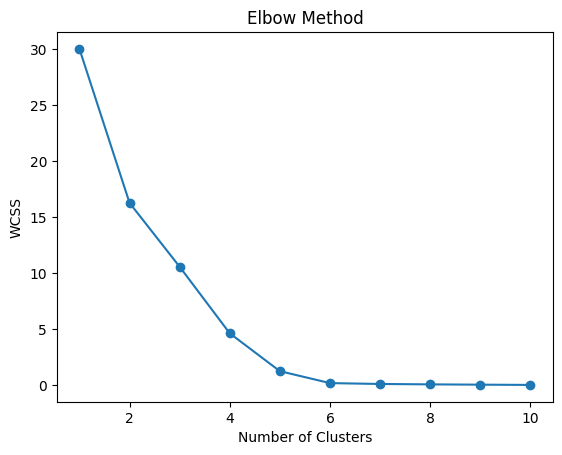

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Create dataset
data = {
    'Income': [15,16,17,18,19,20,60,62,63,65,80,82,85,88,90],
    'Spending': [39,81,6,77,40,76,50,52,48,55,20,18,85,90,15]
}

df = pd.DataFrame(data)

# Display dataset
print(df)

# Select features
X = df[['Income', 'Spending']]

# Feature scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Elbow method
wcss = []

for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot elbow graph
plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [3]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

df['Cluster'] = kmeans.fit_predict(X_scaled)

print(df)

    Income  Spending  Cluster
0       15        39        0
1       16        81        2
2       17         6        0
3       18        77        2
4       19        40        0
5       20        76        2
6       60        50        1
7       62        52        1
8       63        48        1
9       65        55        1
10      80        20        3
11      82        18        3
12      85        85        1
13      88        90        1
14      90        15        3


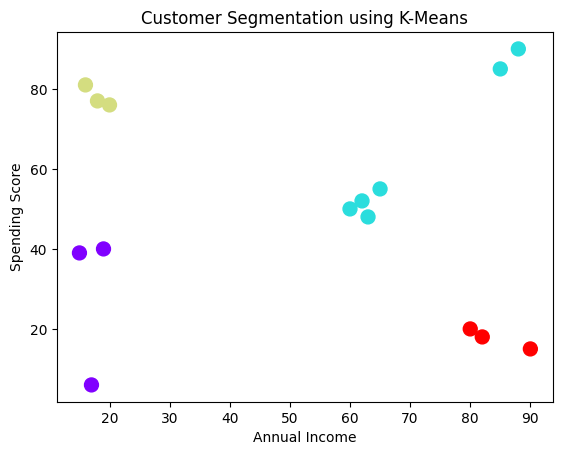

In [4]:
plt.scatter(
    df['Income'],
    df['Spending'],
    c=df['Cluster'],
    cmap='rainbow',
    s=100
)

plt.xlabel('Annual Income')
plt.ylabel('Spending Score')
plt.title('Customer Segmentation using K-Means')

plt.show()